# 31 · Circuit vs emulation

**Question.** Does the GQSP circuit, simulated (T1), prepare what the exact emulation (T2) predicts, so that T2 can stand in for it where the circuit is too large to simulate?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p4_t1", "p5_t1", "p4_stateprep", "p5_stateprep")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p4_t1: 96 records, 91 ok
p5_t1: 90 records, 84 ok
p4_stateprep: 231 records, 231 ok
p5_stateprep: 338 records, 338 ok


In [2]:
from IPython.display import Markdown, display

from pihm.pipeline.results import AGREEMENT_BAR, PHASES_BAR
from pihm.qsp.prepare import RESOLVABLE_PROBABILITY

circuits = {
    form: results.rows("p4_t1", regime=form) + results.rows("p5_t1", regime=form)
    for form in ("standard", "descriptor")
}
forms = {
    form: [
        r | {"floor": r["filtered_agreement"] / r["success_probability"] ** 0.5}
        for r in rows
        if r["status"] == "ok"
    ]
    for form, rows in circuits.items()
}
emulations = results.rows("p4_stateprep") + results.rows("p5_stateprep")


def verdict(form):
    """Return one line: the circuit's agreement before normalising, and on the prepared state."""
    ok = forms[form]
    refused = sum(r["status"] == "infeasible" for r in circuits[form])
    raw = [r for r in ok if r["filtered_agreement"] > AGREEMENT_BAR]
    judged = [r for r in ok if r["success_probability"] >= RESOLVABLE_PROBABILITY]
    missed = [r for r in judged if r["t2_agreement"] > AGREEMENT_BAR]
    over = max((r["t2_agreement"] / r["floor"] for r in missed), default=None)
    at_floor = f", each within {over:.2g} times its rounding floor" if over else ""
    degrees = ", ".join(str(r["degree"]) for r in raw)
    misses = f" (misses at degree {degrees})" if raw else ""
    return (
        f"- The {form} form, {len(ok)} circuits simulated ({refused} refused as beyond the "
        f"budget): {len(ok) - len(raw)} agree with T2 before normalising{misses}, and "
        f"{len(judged) - len(missed)} of the {len(judged)} with p ≥ "
        f"{RESOLVABLE_PROBABILITY:g} on the prepared state{at_floor}."
    )


phases = [r["phases_max_error"] for r in emulations if isinstance(r.get("phases_max_error"), float)]
lines = [
    f"Against the bar {AGREEMENT_BAR:g}:",
    *(verdict(form) for form in forms),
    f"- The GQSP phases realise the target polynomial to {max(phases):.1e} or better in all "
    f"{len(phases)} emulations ({sum(e > PHASES_BAR for e in phases)} over the bar "
    f"{PHASES_BAR:g}).",
]
display(Markdown("\n".join(lines)))

Against the bar 1e-10:
- The standard form, 125 circuits simulated (5 refused as beyond the budget): 119 agree with T2 before normalising (misses at degree 81195, 81195, 211722, 211722, 211721, 211721), and 90 of the 102 with p ≥ 1e-12 on the prepared state, each within 1 times its rounding floor.
- The descriptor form, 50 circuits simulated (6 refused as beyond the budget): 50 agree with T2 before normalising, and 48 of the 50 with p ≥ 1e-12 on the prepared state, each within 0.69 times its rounding floor.
- The GQSP phases realise the target polynomial to 7.0e-13 or better in all 569 emulations (0 over the bar 1e-12).

Left, the circuit's output before normalising against T2's, from a unit input, by the filter's
degree. Right, the prepared states compared, against the rounding floor that normalising by √p
sets in double precision; only records with p above the resolvable level are shown.

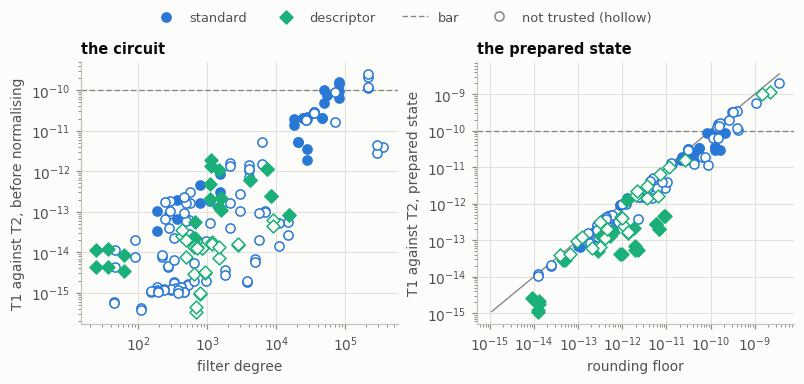

In [3]:
resolvable = {
    form: [r for r in rows if r["success_probability"] >= RESOLVABLE_PROBABILITY]
    for form, rows in forms.items()
}
plotting.checks(
    [
        plotting.Check(
            forms,
            "degree",
            "filtered_agreement",
            "filter degree",
            "T1 against T2, before normalising",
            "the circuit",
            diagonal=False,
            bar=AGREEMENT_BAR,
            bar_label="bar",
        ),
        plotting.Check(
            resolvable,
            "floor",
            "t2_agreement",
            "rounding floor",
            "T1 against T2, prepared state",
            "the prepared state",
            bar=AGREEMENT_BAR,
            bar_label="bar",
        ),
    ]
);

**What this does not show.** The circuit is simulated where it fits: every rung at the smallest
resolution, and larger where the budget allows. The standard form's circuits run both filters, the
reproduction's QITE and the minimax filter. Each geometric initial state is its own record here.